In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

In [2]:
df_path = "/content/drive/MyDrive/Model/Data sebelum imputasi/Data konsentrasi perjam DKI4 Lubang Buaya.xlsx"
df = pd.read_excel(df_path)
df = df.replace('---', np.nan)
pollutant_cols = ['PM10', 'PM2.5', 'SO2', 'CO', 'O3', 'NO', 'NO2', 'NOX']
df[pollutant_cols] = df[pollutant_cols].replace(0, np.nan)
df.head(10)

/tmp/ipykernel_507/1665750715.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.replace('---', np.nan)


,datetime,PM10,PM2.5,SO2,CO,O3,NO,NO2,NOX,Suhu Udara (°C),Curah Hujan (mm),Suhu Titik Embun (°C),Kelembaban Relatif (%),Kecepatan Angin (m/s),Radiasi Matahari (W/m²)
0,2020-01-01 00:00:00,47.71,54.71,58.72,0.77,31.08,2.23,19.41,11.11,24.090000,1.00,23.120001,94.320000,0.543,0.000000
1,2020-01-01 01:00:00,51.61,45.42,57.57,0.09,52.97,1.12,5.49,3.51,24.100000,0.83,23.280001,95.180000,0.906,0.000000
2,2020-01-01 02:00:00,54.48,17.46,56.07,NaN,62.2,0.43,2.28,0.84,24.490000,0.70,23.059999,91.760002,1.337,0.000000
3,2020-01-01 03:00:00,58.06,7.57,56.02,NaN,59.05,0.14,0.47,0.42,24.629999,0.68,23.059999,90.989998,1.667,0.000000
4,2020-01-01 04:00:00,53.84,4.97,56.17,NaN,67.07,0.37,NaN,NaN,24.959999,0.67,23.299999,90.519997,1.843,0.000000
5,2020-01-01 05:00:00,51.23,3.35,56.49,NaN,69.15,0.98,NaN,NaN,26.280001,0.78,23.510000,84.769997,2.601,0.000000
6,2020-01-01 06:00:00,41.51,1.08,55.83,NaN,63.58,0.38,NaN,0.09,26.469999,1.67,23.420000,83.370003,1.914,33.470001
7,2020-01-01 07:00:00,36.68,1.06,56.36,NaN,63.16,0.37,1.39,0.58,25.809999,1.06,23.389999,86.529999,1.453,94.809998
8,2020-01-01 08:00:00,30.29,0.66,56.13,0.06,48.44,1.59,7.23,4.7,26.180000,1.02,23.280001,84.089996,1.292,143.009995
9,2020-01-01 09:00:00,24.07,4.07,56.48,0.35,45.92,3.48,9.99,7.46,25.969999,0.77,23.090000,84.169998,1.154,195.309998


In [3]:
for col in df.columns:
    if col != 'datetime':
        df[col] = pd.to_numeric(df[col], errors='coerce')
print(df.dtypes)

datetime                   datetime64[ns]
PM10                              float64
PM2.5                             float64
SO2                               float64
CO                                float64
O3                                float64
NO                                float64
NO2                               float64
NOX                               float64
Suhu Udara (°C)                   float64
Curah Hujan (mm)                  float64
Suhu Titik Embun (°C)             float64
Kelembaban Relatif (%)            float64
Kecepatan Angin (m/s)             float64
Radiasi Matahari (W/m²)           float64
dtype: object


In [4]:
df.isnull().sum()

,0
datetime,0
PM10,7276
PM2.5,1327
SO2,1575
CO,2159
O3,2474
NO,2016
NO2,1686
NOX,1682
Suhu Udara (°C),0


In [5]:
missing_percent = df.isnull().mean() * 100
missing_percent_str = missing_percent.round(2).astype(str) + ' %'
(missing_percent.round(2)).astype(str) + ' %'

,0
datetime,0.0 %
PM10,16.59 %
PM2.5,3.03 %
SO2,3.59 %
CO,4.92 %
O3,5.64 %
NO,4.6 %
NO2,3.85 %
NOX,3.84 %
Suhu Udara (°C),0.0 %


In [6]:
df_numeric = df.select_dtypes(include='number')
df_numeric.describe().round(2)

,PM10,PM2.5,SO2,CO,O3,NO,NO2,NOX,Suhu Udara (°C),Curah Hujan (mm),Suhu Titik Embun (°C),Kelembaban Relatif (%),Kecepatan Angin (m/s),Radiasi Matahari (W/m²)
count,36572.00,42521.00,42273.00,41689.00,41374.00,41832.00,42162.00,42166.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00
mean,69.70,47.65,43.14,1.18,53.21,16.70,23.67,23.83,26.39,0.30,22.85,81.98,1.41,208.83
std,41.81,35.41,12.33,0.88,52.74,21.89,15.52,19.38,2.64,0.75,1.08,11.88,0.74,282.32
min,1.04,0.34,0.04,0.01,0.01,0.02,0.01,0.02,19.57,0.00,15.45,34.93,0.01,0.00
25%,43.70,24.70,34.47,0.56,13.06,4.22,12.27,10.48,24.22,0.00,22.31,73.36,0.90,0.00
50%,64.54,41.14,41.44,1.03,34.76,7.87,20.38,17.89,25.71,0.04,22.96,85.83,1.27,12.61
75%,87.99,61.80,53.24,1.55,79.51,19.19,31.77,31.38,28.54,0.21,23.55,91.84,1.79,411.25
max,922.97,985.00,116.76,43.70,439.78,438.39,135.85,341.63,35.34,15.73,26.48,99.22,5.82,1059.24


In [7]:
df['datetime'] = pd.to_datetime(df['datetime'], errors='coerce')
df_ts = df.set_index('datetime')
df_ts = df_ts.apply(pd.to_numeric, errors='coerce')

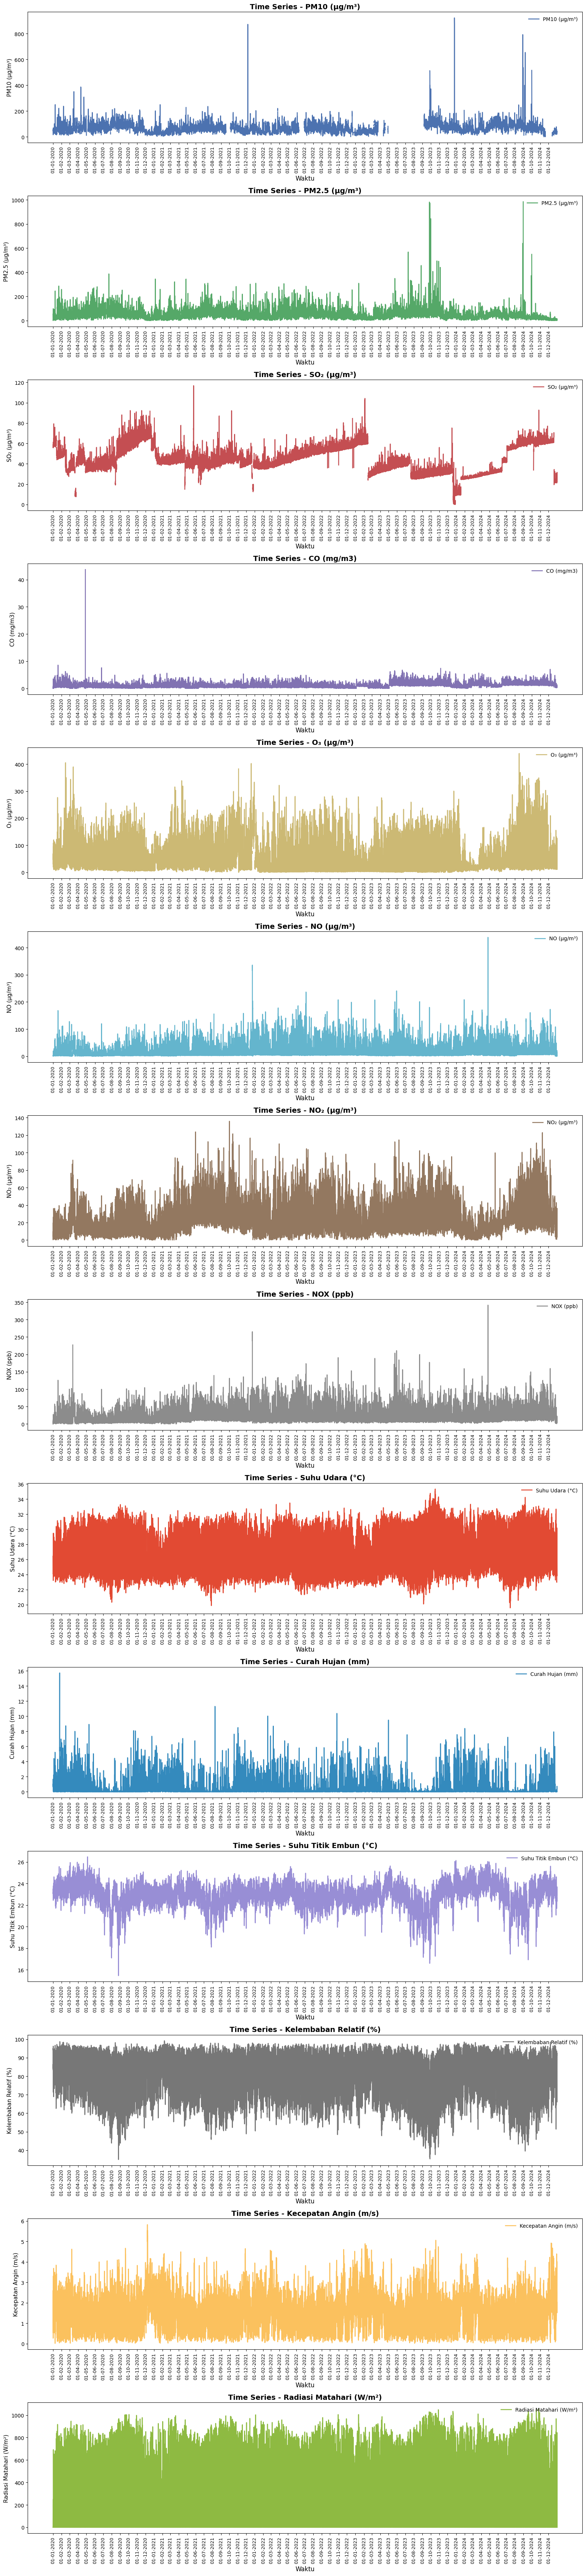

In [8]:
if not isinstance(df_ts.index, pd.DatetimeIndex):
    df_ts.index = pd.to_datetime(df_ts.index)

df_ts = df_ts.sort_index()
hours = (df_ts.index - df_ts.index.min()) / pd.Timedelta(hours=1)
xticks = pd.date_range(start=df_ts.index.min().normalize(),
                       end=df_ts.index.max().normalize(), freq="MS")
labels = [d.strftime('%d-%m-%Y') for d in xticks]


xticks_hours = (xticks - df_ts.index.min()) / pd.Timedelta(hours=1)

colors = [
    "#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974",
    "#64B5CD", "#937860", "#8C8C8C", "#E24A33", "#348ABD",
    "#988ED5", "#777777", "#FBC15E", "#8EBA42", "#FFB5B8"
]
if len(df_ts.columns) > len(colors):
    colors = (colors * (len(df_ts.columns) // len(colors) + 1))[:len(df_ts.columns)]

label_map = {
    'datetime': 'Tanggal & Waktu',
    'PM10': 'PM10 (µg/m³)',
    'PM2.5': 'PM2.5 (µg/m³)',
    'SO2': 'SO₂ (µg/m³)',
    'CO': 'CO (mg/m3)',
    'O3': 'O₃ (µg/m³)',
    'NO': 'NO (µg/m³)',
    'NO2': 'NO₂ (µg/m³)',
    'NOX': 'NOX (ppb)'
}

fig, axes = plt.subplots(
    nrows=len(df_ts.columns),
    figsize=(16, 5 * len(df_ts.columns)),
    sharex=False
)

if len(df_ts.columns) == 1:
    axes = [axes]

for ax, col, color in zip(axes, df_ts.columns, colors):
    ax.plot(hours, df_ts[col], color=color, linewidth=1.8, label=label_map.get(col, col))
    ax.set_title(f"Time Series - {label_map.get(col, col)}", fontsize=14, fontweight='bold')
    ax.set_ylabel(label_map.get(col, col), fontsize=11)
    ax.legend(loc="upper right", fontsize=10, frameon=False)
    ax.set_xticks(xticks_hours)
    ax.set_xticklabels(labels, rotation=90, ha="center", fontsize=9)

for ax in axes:
    ax.set_xlabel("Waktu", fontsize=12)

plt.tight_layout()
plt.show()

In [9]:
df['datetime'] = pd.to_datetime(df['datetime'])
datetime_index = df['datetime']
numeric_cols = df.select_dtypes(include=[np.number]).columns
df_numeric = df[numeric_cols]

scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_numeric)

In [10]:
imputer = KNNImputer(n_neighbors=5)
df_imputed_scaled = imputer.fit_transform(df_scaled)

In [11]:
df_imputed_numeric = pd.DataFrame(
    scaler.inverse_transform(df_imputed_scaled),
    columns=numeric_cols
)

In [12]:
df_imputed = df_imputed_numeric.copy()
df_imputed.index = datetime_index
df_imputed.head(10)

,PM10,PM2.5,SO2,CO,O3,NO,NO2,NOX,Suhu Udara (°C),Curah Hujan (mm),Suhu Titik Embun (°C),Kelembaban Relatif (%),Kecepatan Angin (m/s),Radiasi Matahari (W/m²)
datetime,,,,,,,,,,,,,,
2020-01-01 00:00:00,47.71,54.71,58.72,0.770,31.08,2.23,19.410,11.110,24.090000,1.00,23.120001,94.320000,0.543,0.000000
2020-01-01 01:00:00,51.61,45.42,57.57,0.090,52.97,1.12,5.490,3.510,24.100000,0.83,23.280001,95.180000,0.906,0.000000
2020-01-01 02:00:00,54.48,17.46,56.07,0.530,62.20,0.43,2.280,0.840,24.490000,0.70,23.059999,91.760002,1.337,0.000000
2020-01-01 03:00:00,58.06,7.57,56.02,0.582,59.05,0.14,0.470,0.420,24.629999,0.68,23.059999,90.989998,1.667,0.000000
2020-01-01 04:00:00,53.84,4.97,56.17,0.762,67.07,0.37,16.204,10.116,24.959999,0.67,23.299999,90.519997,1.843,0.000000
2020-01-01 05:00:00,51.23,3.35,56.49,0.828,69.15,0.98,8.900,7.518,26.280001,0.78,23.510000,84.769997,2.601,0.000000
2020-01-01 06:00:00,41.51,1.08,55.83,0.668,63.58,0.38,4.062,0.090,26.469999,1.67,23.420000,83.370003,1.914,33.470001
2020-01-01 07:00:00,36.68,1.06,56.36,0.402,63.16,0.37,1.390,0.580,25.809999,1.06,23.389999,86.529999,1.453,94.809998
2020-01-01 08:00:00,30.29,0.66,56.13,0.060,48.44,1.59,7.230,4.700,26.180000,1.02,23.280001,84.089996,1.292,143.009995


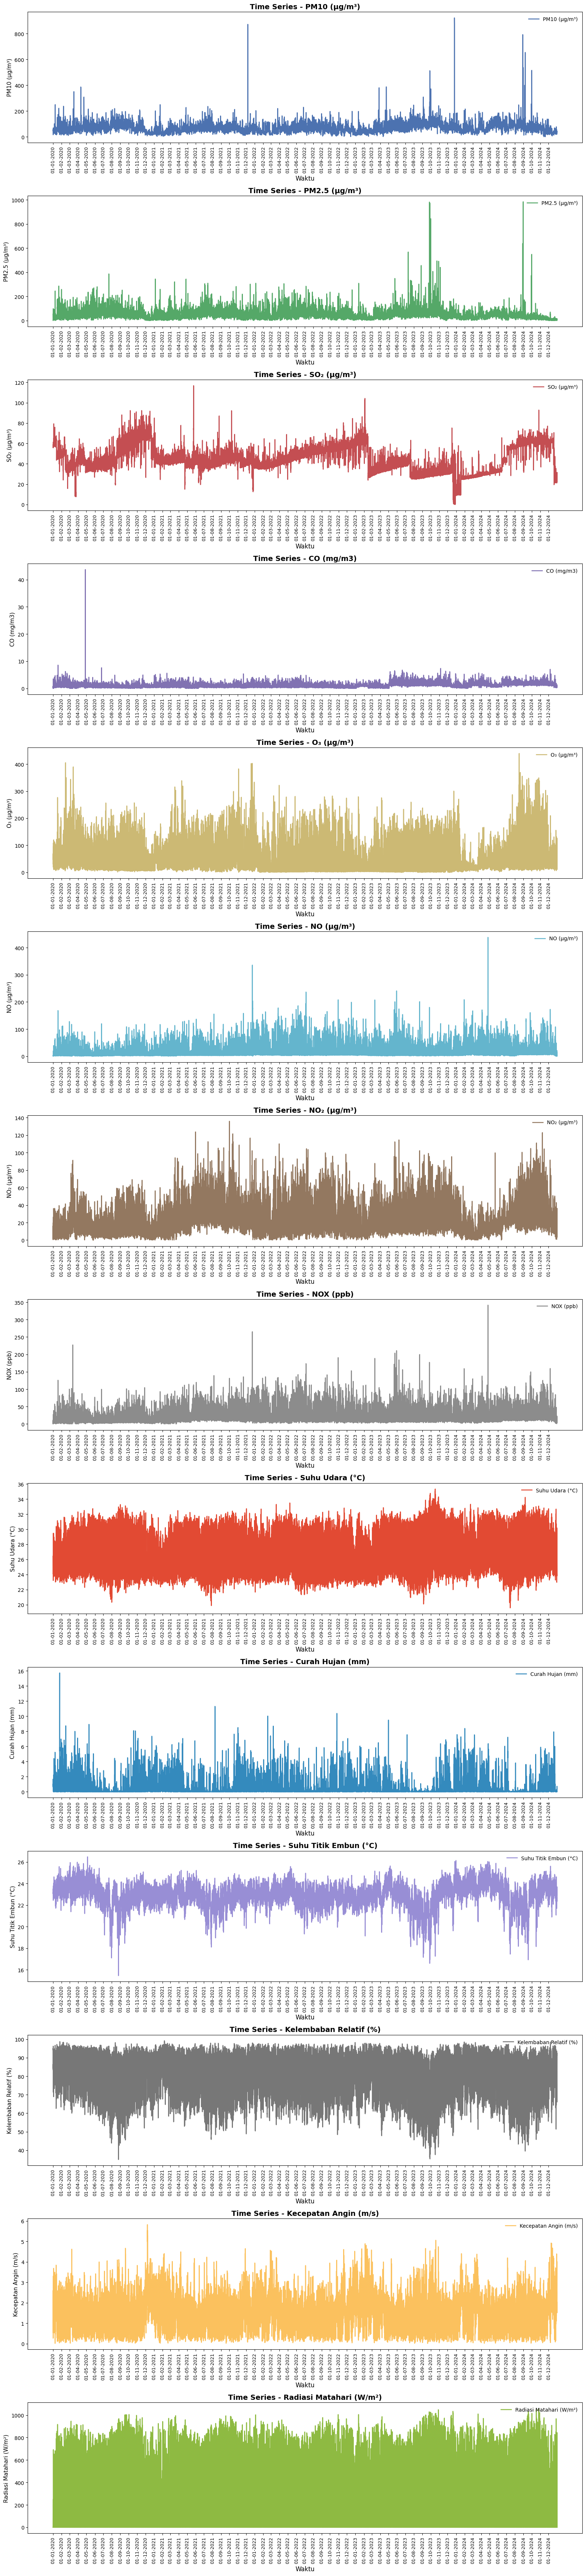

In [13]:
if not isinstance(df_imputed.index, pd.DatetimeIndex):
    df_imputed.index = pd.to_datetime(df_imputed.index)

df_imputed = df_imputed.sort_index()

hours = (df_imputed.index - df_imputed.index.min()) / pd.Timedelta(hours=1)

xticks = pd.date_range(start=df_imputed.index.min().normalize(),
                       end=df_imputed.index.max().normalize(),
                       freq="MS")
labels = [d.strftime('%d-%m-%Y') for d in xticks]
xticks_hours = (xticks - df_imputed.index.min()) / pd.Timedelta(hours=1)

colors = [
    "#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974",
    "#64B5CD", "#937860", "#8C8C8C", "#E24A33", "#348ABD",
    "#988ED5", "#777777", "#FBC15E", "#8EBA42", "#FFB5B8"
]
if len(df_imputed.columns) > len(colors):
    colors = (colors * (len(df_imputed.columns) // len(colors) + 1))[:len(df_imputed.columns)]

label_map = {
    'datetime': 'Tanggal & Waktu',
    'PM10': 'PM10 (µg/m³)',
    'PM2.5': 'PM2.5 (µg/m³)',
    'SO2': 'SO₂ (µg/m³)',
    'CO': 'CO (mg/m3)',
    'O3': 'O₃ (µg/m³)',
    'NO': 'NO (µg/m³)',
    'NO2': 'NO₂ (µg/m³)',
    'NOX': 'NOX (ppb)'
}

fig, axes = plt.subplots(
    nrows=len(df_imputed.columns),
    figsize=(16, 5 * len(df_imputed.columns)),
    sharex=False
)

if len(df_imputed.columns) == 1:
    axes = [axes]

for ax, col, color in zip(axes, df_imputed.columns, colors):
    ax.plot(hours, df_imputed[col], color=color, linewidth=1.8, label=label_map.get(col, col))
    ax.set_title(f"Time Series - {label_map.get(col, col)}", fontsize=14, fontweight='bold')
    ax.set_ylabel(label_map.get(col, col), fontsize=11)
    ax.legend(loc="upper right", fontsize=10, frameon=False)
    ax.set_xticks(xticks_hours)
    ax.set_xticklabels(labels, rotation=90, ha="center", fontsize=9)

for ax in axes:
    ax.set_xlabel("Waktu", fontsize=12)

plt.tight_layout()
plt.show()

In [14]:
df_imputed.describe().round(2)

,PM10,PM2.5,SO2,CO,O3,NO,NO2,NOX,Suhu Udara (°C),Curah Hujan (mm),Suhu Titik Embun (°C),Kelembaban Relatif (%),Kecepatan Angin (m/s),Radiasi Matahari (W/m²)
count,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00
mean,70.65,47.67,43.13,1.18,52.60,16.58,23.57,23.76,26.39,0.30,22.85,81.98,1.41,208.83
std,40.01,35.04,12.19,0.87,52.29,21.62,15.38,19.21,2.64,0.75,1.08,11.88,0.74,282.32
min,1.04,0.34,0.04,0.01,0.01,0.02,0.01,0.02,19.57,0.00,15.45,34.93,0.01,0.00
25%,45.38,25.10,34.67,0.56,12.90,4.22,12.34,10.48,24.22,0.00,22.31,73.36,0.90,0.00
50%,66.30,41.36,41.50,1.02,33.88,7.86,20.37,17.90,25.71,0.04,22.96,85.83,1.27,12.61
75%,88.93,61.62,52.92,1.54,78.80,19.18,31.61,31.32,28.54,0.21,23.55,91.84,1.79,411.25
max,922.97,985.00,116.76,43.70,439.78,438.39,135.85,341.63,35.34,15.73,26.48,99.22,5.82,1059.24


In [15]:
df_imputed.loc[:, ~df_imputed.columns.isin(['NO', 'NOX'])].describe().round(2)

,PM10,PM2.5,SO2,CO,O3,NO2,Suhu Udara (°C),Curah Hujan (mm),Suhu Titik Embun (°C),Kelembaban Relatif (%),Kecepatan Angin (m/s),Radiasi Matahari (W/m²)
count,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00
mean,70.65,47.67,43.13,1.18,52.60,23.57,26.39,0.30,22.85,81.98,1.41,208.83
std,40.01,35.04,12.19,0.87,52.29,15.38,2.64,0.75,1.08,11.88,0.74,282.32
min,1.04,0.34,0.04,0.01,0.01,0.01,19.57,0.00,15.45,34.93,0.01,0.00
25%,45.38,25.10,34.67,0.56,12.90,12.34,24.22,0.00,22.31,73.36,0.90,0.00
50%,66.30,41.36,41.50,1.02,33.88,20.37,25.71,0.04,22.96,85.83,1.27,12.61
75%,88.93,61.62,52.92,1.54,78.80,31.61,28.54,0.21,23.55,91.84,1.79,411.25
max,922.97,985.00,116.76,43.70,439.78,135.85,35.34,15.73,26.48,99.22,5.82,1059.24


In [ ]:
df_imputed['datetime'] = df_imputed.index
df_imputed.to_excel("/content/drive/MyDrive/Model/Data Imputasi/df_imputed.xlsx", index=False)